# Лабораторная работа №5

**Задание [5.1.1] и подпункты [1.2]–[1.5].**

Генерация синтетических датасетов `df_Z` (классы `L` и `M`) и их первичный анализ:
табличная статистика, 1D raincloud+boxplot, 2D scatterplot с маргинальными плотностями,
heat-map корреляций Пирсона и Спирмена.

Визуализации построены с помощью библиотек из папки `plots/`:
`plots/raincloud.py`, `plots/scatterplot.py` (и при необходимости `plots/upset.py`).


In [1]:
# ============================================================
# Импорты и общие настройки
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from scipy.stats import gaussian_kde
from matplotlib.text import Text
from IPython.display import display

from plots import raincloud, scatterplot

%matplotlib inline
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 60)
sns.set_theme(style='whitegrid', context='notebook')
print('numpy', np.__version__, '| pandas', pd.__version__)


[font] discovered 'Nimbus Sans' at /usr/share/fonts/urw-base35/NimbusSans-Regular.otf
numpy 2.5.4 | pandas 3.0.6


## [5.1.1] Генерация датасетов `df_Z`

Класс `L` — 1000 точек вдоль отрезка `[(-A,...,-A), (+A,...,+A)]`;
класс `M` — исходно вдоль отрезка `[(+A,-A,+A,-A,+A,-A), (-A,+A,-A,+A,-A,+A)]`,
затем сдвинут **вдоль своего отрезка** на расстояние `Z`.

Дисперсии по признакам: `Var(X_k) = A / k`, `k = 1..6`
(`Var(X1)=A`, `Var(X2)=A/2`, ..., `Var(X6)=A/6`).
Шум добавляется функцией `numpy.random.Generator.multivariate_normal`.

Сдвиг класса `M`: `M_shifted = M_original + Z * u`, где `u` — единичный вектор
направления отрезка класса `M`. При `Z = A/10` классы почти совпадают,
при `Z = A` умеренно разнесены, при `Z = 10A` сильно разнесены.


In [2]:
# ============================================================
# [5.1.1] Генерация df_Z с помощью multivariate_normal
# ============================================================
RANDOM_STATE = 42          # произвольный, но фиксированный seed
A = 10.0                   # масштаб отрезков и дисперсий
N_FEATURES = 6
N_PER_CLASS = 1000
FEATURES = [f'X{k}' for k in range(1, N_FEATURES + 1)]
CLASS_COL = 'class'
CLASSES = ['L', 'M']

# Дисперсии по признакам: X1 -> A, Xk -> A/k (k=2..6)
VARIANCES = np.array([A / k for k in range(1, N_FEATURES + 1)])
COV = np.diag(VARIANCES)

# Отрезки классов
SEG_L = (np.full(N_FEATURES, -A), np.full(N_FEATURES, +A))
SEG_M = (np.array([+A, -A, +A, -A, +A, -A]),
         np.array([-A, +A, -A, +A, -A, +A]))

# Единичный вектор направления отрезка M (для сдвига на расстояние Z)
DIR_M = SEG_M[1] - SEG_M[0]
UNIT_M = DIR_M / np.linalg.norm(DIR_M)

# Значения сдвига Z = A/10, A, 10A
Z_LABELS = {'A/10': A / 10, 'A': A, '10A': 10 * A}


def sample_along_segment(rng, seg, n, cov):
    """n точек: равномерная позиция вдоль отрезка + гауссов шум multivariate_normal."""
    p0, p1 = seg
    t = rng.random(n)                       # параметр вдоль отрезка [0, 1]
    centers = p0 + t[:, None] * (p1 - p0)   # центры точек на отрезке
    noise = rng.multivariate_normal(        # требуемая функция numpy
        mean=np.zeros(N_FEATURES), cov=cov, size=n
    )
    return centers + noise


def make_df_z(z_label, seed=RANDOM_STATE):
    """Датасет df_Z: класс L на своём отрезке, класс M сдвинут на Z вдоль своего отрезка.

    Класс M строится «аналогично» L: те же положения t вдоль отрезка и та же
    реализация шума, но знаки признаков чередуются согласно отрезку M.
    """
    rng = np.random.default_rng(seed)
    t = rng.random(N_PER_CLASS)
    noise = rng.multivariate_normal(np.zeros(N_FEATURES), COV, size=N_PER_CLASS)

    X_L = SEG_L[0] + t[:, None] * (SEG_L[1] - SEG_L[0]) + noise
    X_M = SEG_M[0] + t[:, None] * (SEG_M[1] - SEG_M[0]) + noise
    X_M = X_M + Z_LABELS[z_label] * UNIT_M  # сдвиг класса M на расстояние Z

    df_L = pd.DataFrame(X_L, columns=FEATURES)
    df_L[CLASS_COL] = 'L'
    df_M = pd.DataFrame(X_M, columns=FEATURES)
    df_M[CLASS_COL] = 'M'
    return pd.concat([df_L, df_M], ignore_index=True)


DF_Z = {label: make_df_z(label) for label in Z_LABELS}

print(f'A = {A}, random_state = {RANDOM_STATE}')
print(f'Дисперсии по признакам: {dict(zip(FEATURES, VARIANCES))}')
print(f'Единичный вектор сдвига M: {np.round(UNIT_M, 4)}')
for label, z in Z_LABELS.items():
    df = DF_Z[label]
    print(f'\ndf_{label}: Z = {z:g}, shape = {df.shape}, '
          f'классы = {df[CLASS_COL].value_counts().to_dict()}')
    print(df.head(3).to_string())


A = 10.0, random_state = 42
Дисперсии по признакам: {'X1': np.float64(10.0), 'X2': np.float64(5.0), 'X3': np.float64(3.3333333333333335), 'X4': np.float64(2.5), 'X5': np.float64(2.0), 'X6': np.float64(1.6666666666666667)}
Единичный вектор сдвига M: [-0.4082  0.4082 -0.4082  0.4082 -0.4082  0.4082]

df_A/10: Z = 1, shape = (2000, 7), классы = {'L': 1000, 'M': 1000}
         X1        X2        X3        X4        X5        X6 class
0  3.132103  7.546048  5.542313  5.031982  5.328957  5.767170     L
1  0.728107 -3.457856 -3.124101  0.524220 -1.805564 -3.051566     L
2  8.575417  8.208085  4.377267  7.534801  8.212230  7.655289     L

df_A: Z = 10, shape = (2000, 7), классы = {'L': 1000, 'M': 1000}
         X1        X2        X3        X4        X5        X6 class
0  3.132103  7.546048  5.542313  5.031982  5.328957  5.767170     L
1  0.728107 -3.457856 -3.124101  0.524220 -1.805564 -3.051566     L
2  8.575417  8.208085  4.377267  7.534801  8.212230  7.655289     L

df_10A: Z = 100, shape

## [1.2] Табличная статистика по датасету

Для каждого `df_Z` выводятся:
- размерность (объекты × признаки) и тип каждого признака;
- количество классов и объектов в каждом классе;
- иные оценки выборки (среднее, СКО, квантили, IQR, Range, асимметрия, эксцесс);
- число объектов с `NaN` по классам;
- число объектов с `0` по классам.


In [3]:
# ============================================================
# [1.2] Статистика датасетов df_Z (табличное представление, как в 4.ipynb)
# ============================================================
def show_dataset_statistics(df, label):
    print('\n' + '=' * 78)
    print(f'СТАТИСТИКА df_{label}')
    print('=' * 78)

    # --- общая информация о размере и типах ---
    summary = pd.DataFrame({
        'Показатель': [
            'Число объектов',
            'Число количественных признаков',
            'Число классов',
            'Размерность df (объекты × столбцы)',
            'Сдвиг Z',
        ],
        'Значение': [
            len(df), len(FEATURES), df[CLASS_COL].nunique(), str(df.shape),
            f'{Z_LABELS[label]:g}',
        ],
    })
    print('Общая информация')
    display(summary)

    print('Типы признаков и целевого столбца')
    display(pd.DataFrame({'Тип': df.dtypes.astype(str)}))

    print('Количество объектов в каждом классе')
    display(df[CLASS_COL].value_counts().sort_index()
              .rename('Количество объектов').to_frame())

    print('Описательные оценки количественных признаков (весь датасет)')
    display(df[FEATURES].describe().T.round(4))

    # --- иные оценки выборки: весь датасет и по каждому классу ---
    groups = {'все': df[FEATURES]}
    groups.update({f'класс {c}': df.loc[df[CLASS_COL] == c, FEATURES] for c in CLASSES})
    rows = {}
    for name, g in groups.items():
        desc = g.describe().T
        desc['Q1'] = g.quantile(0.25)
        desc['median'] = g.median()
        desc['Q3'] = g.quantile(0.75)
        desc['IQR'] = desc['Q3'] - desc['Q1']
        desc['Range'] = desc['max'] - desc['min']
        desc['skew'] = g.skew()
        desc['kurt'] = g.kurt()
        rows[name] = desc[['count', 'mean', 'std', 'min', 'Q1', 'median', 'Q3',
                           'max', 'IQR', 'Range', 'skew', 'kurt']].T
    print('Иные оценки выборки (весь датасет и по каждому классу)')
    display(pd.concat(rows, axis=1).round(4))

    # --- объекты с NaN и с нулями по классам (аналог 4.ipynb) ---
    nan_by_class = df.groupby(CLASS_COL)[FEATURES].apply(
        lambda block: block.isna().any(axis=1).sum()
    ).rename('Объектов хотя бы с одним NaN').to_frame()
    print('Объекты с NaN по классам')
    display(nan_by_class)

    zero_by_class = df.groupby(CLASS_COL)[FEATURES].apply(
        lambda block: block.eq(0).any(axis=1).sum()
    ).rename('Объектов хотя бы с одним нулём').to_frame()
    print('Объекты с нулевыми значениями по классам')
    display(zero_by_class)

    # --- детализация по каждому признаку внутри каждого класса ---
    missing_zero_detail = []
    for class_id, block in df.groupby(CLASS_COL):
        for feature in FEATURES:
            missing_zero_detail.append({
                CLASS_COL: class_id,
                'Признак': feature,
                'NaN': int(block[feature].isna().sum()),
                'Нулей': int(block[feature].eq(0).sum()),
            })
    print('Детализация NaN и нулей по признакам')
    display(pd.DataFrame(missing_zero_detail).pivot(
        index='Признак', columns=CLASS_COL, values=['NaN', 'Нулей']
    ))


for label, df in DF_Z.items():
    show_dataset_statistics(df, label)



СТАТИСТИКА df_A/10
Общая информация


,Показатель,Значение
0,Число объектов,2000
1,Число количественных признаков,6
2,Число классов,2
3,Размерность df (объекты × столбцы),"(2000, 7)"
4,Сдвиг Z,1


Типы признаков и целевого столбца


,Тип
X1,float64
X2,float64
X3,float64
X4,float64
X5,float64
X6,float64
class,str


Количество объектов в каждом классе


,Количество объектов
class,
L,1000
M,1000


... (38 outputs left out)

Объекты с нулевыми значениями по классам


,Объектов хотя бы с одним нулём
class,
L,0
M,0


Детализация NaN и нулей по признакам


NaN    Нулей   
class     L  M     L  M
Признак                
X1        0  0     0  0
X2        0  0     0  0
X3        0  0     0  0
X4        0  0     0  0
X5        0  0     0  0
X6        0  0     0  0

## [1.3] 1D визуализация: raincloud plot with jittering + boxplot

Для каждого признака каждого `df_Z`:
- сверху — KDE («облако») по классам;
- по центру — scatter с jittering по классам («дождь»);
- снизу — boxplot с медианой, межквартильным размахом (IQR) и размахом (Range).

Параметры boxplot (`boxplot_whiskers`) можно заменять на другие оценки выборки:
`(0, 100)` — полный Range (по умолчанию), `(25, 75)` — IQR, `(10, 90)` — децили и т.д.


Параметры raincloud/boxplot:
  orientation            = horizontal
  boxplot_whiskers       = (0, 100)
  kde_alpha              = 0.32
  kde_bandwidth          = 0.85
  point_alpha            = 0.25
  points_jitter_height   = 0.115
  box_width              = 0.22
  box_line_width         = 1.8
  median_line_width      = 2.5
  random_state           = 42
  show_legend            = True
  figsize                = (14, 12)


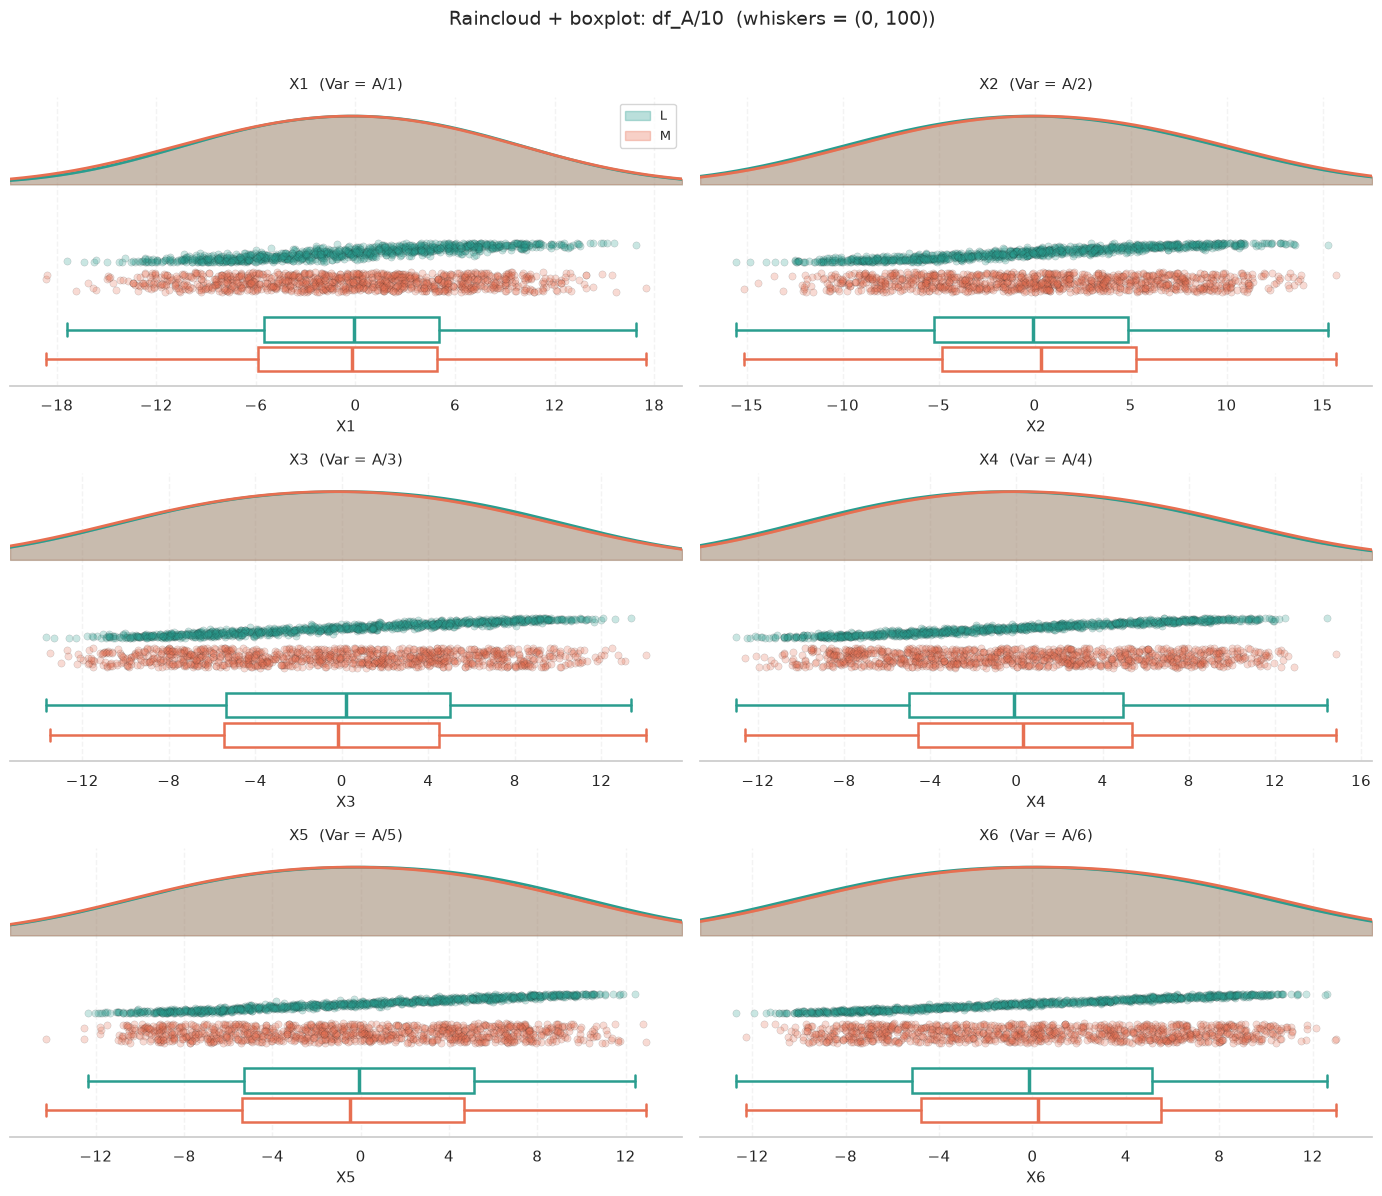

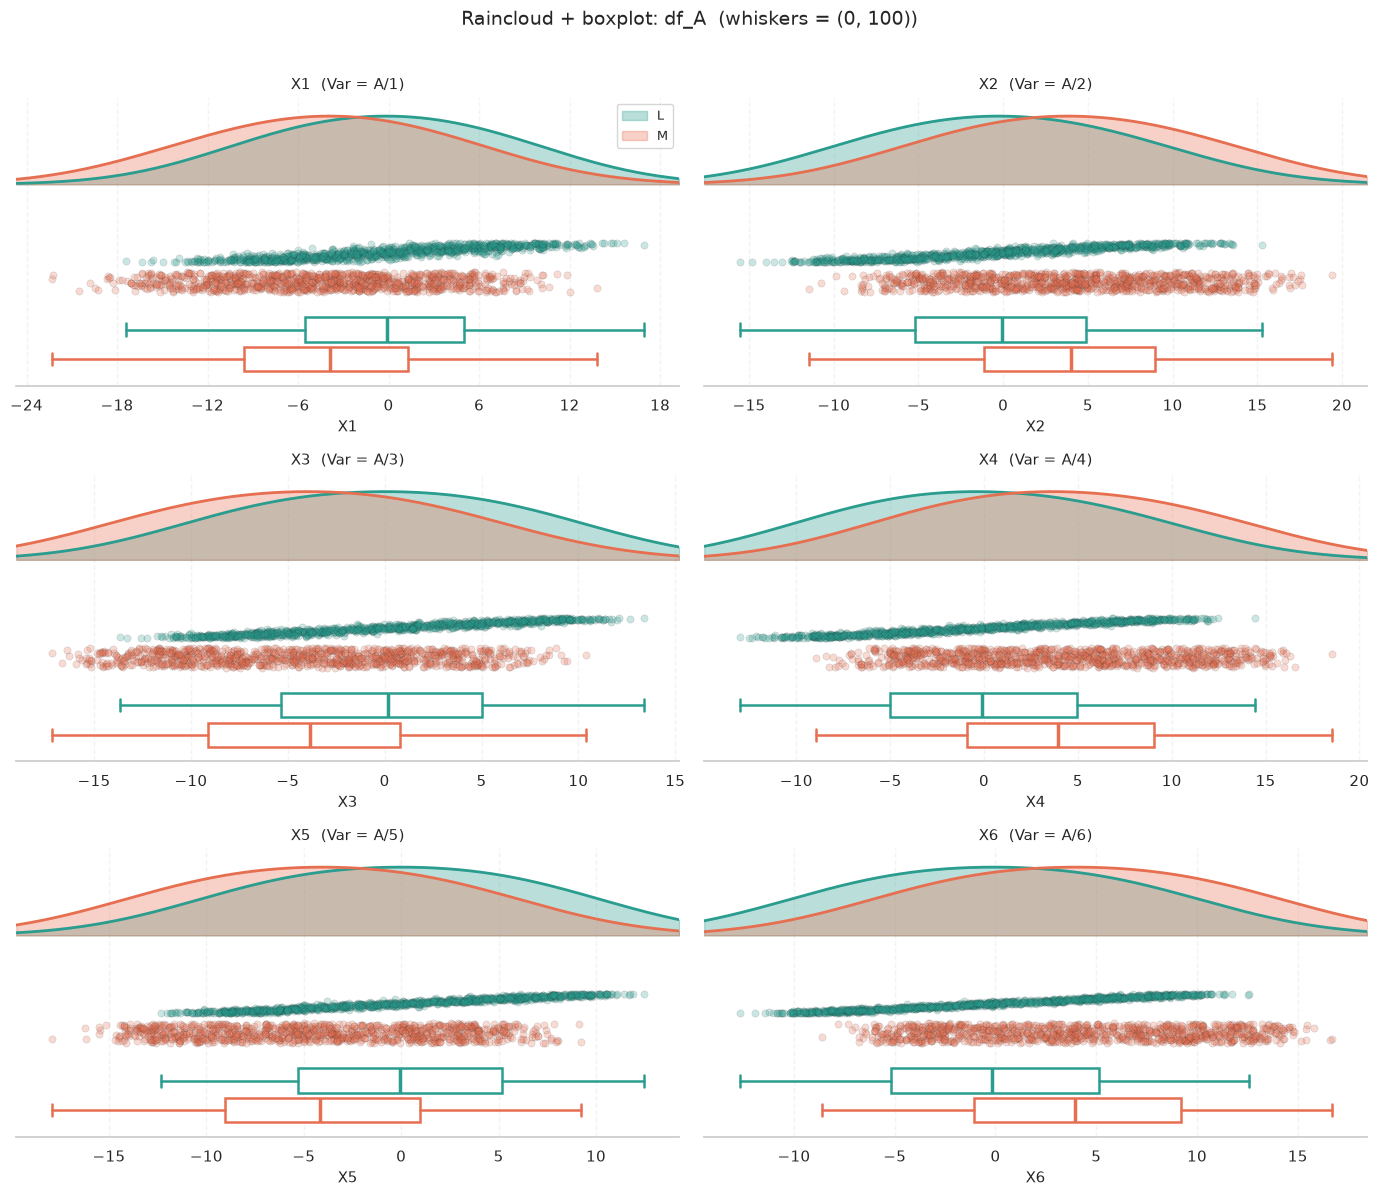

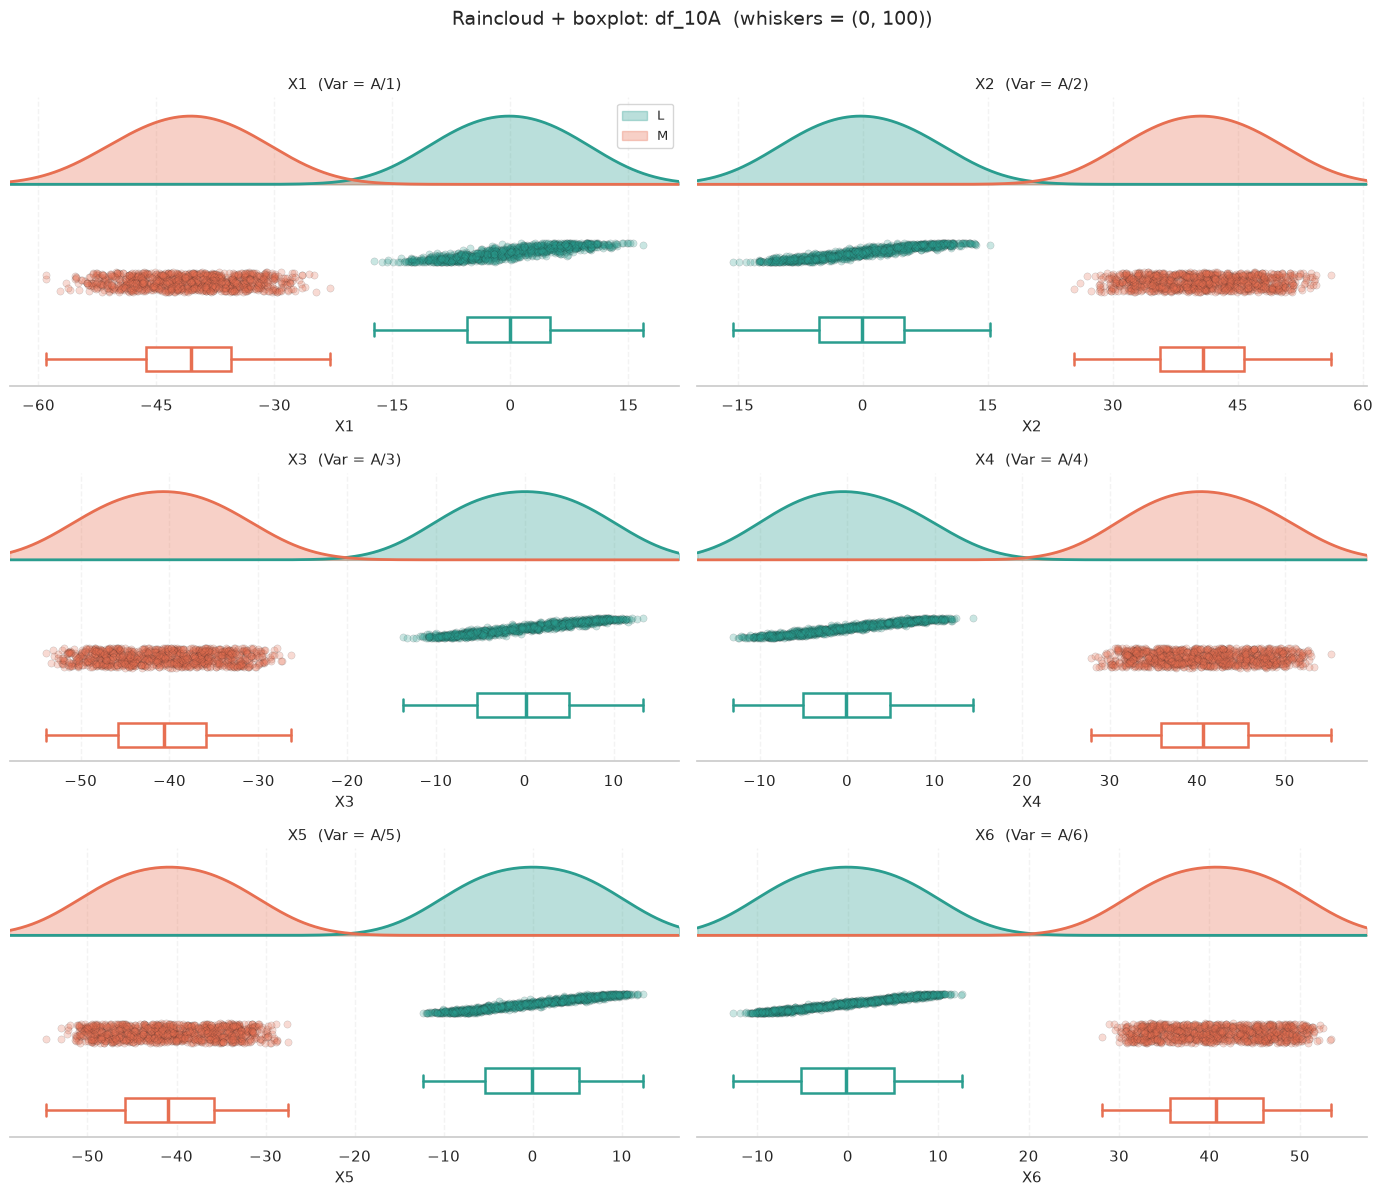

In [4]:
# ============================================================
# [1.3] Raincloud + boxplot по каждому признаку (plots/raincloud.py)
# ============================================================
# --- параметры, регулируемые пользователем ---
RAIN_PARAMS = {
    'orientation': 'horizontal',      # значения признака по оси X
    'boxplot_whiskers': (0, 100),     # (0,100)=Range; можно (25,75)=IQR, (10,90) и др.
    'kde_alpha': 0.32,                # прозрачность KDE-облака
    'kde_bandwidth': 0.85,            # сглаживание KDE
    'point_alpha': 0.25,              # прозрачность jitter-точек (None -> адаптивная)
    'points_jitter_height': 0.115,    # высота разброса точек
    'box_width': 0.22,                # толщина ящика boxplot
    'box_line_width': 1.8,
    'median_line_width': 2.5,
    'random_state': RANDOM_STATE,
    'show_legend': True,              # легенда только на первой оси, чтобы не загромождать
    'figsize': (14, 12),              # размер фигуры на 6 признаков (3x2)
}
CLASS_COLORS = {'L': '#2A9D8F', 'M': '#E76F51'}

print('Параметры raincloud/boxplot:')
for k, v in RAIN_PARAMS.items():
    print(f'  {k:22s} = {v}')


def plot_raincloud_dataset(df, label):
    """Одна фигура на датасет: 6 raincloud+boxplot (по одному на признак)."""
    fig, axes = plt.subplots(nrows=3, ncols=2, figsize=RAIN_PARAMS['figsize'])
    axes = axes.ravel()
    for i, feature in enumerate(FEATURES):
        ax = axes[i]
        raincloud.raincloud_horizontal(
            df, feature,
            class_column=CLASS_COL,
            class_order=CLASSES,
            class_colors=CLASS_COLORS,
            kde_alpha=RAIN_PARAMS['kde_alpha'],
            kde_bandwidth=RAIN_PARAMS['kde_bandwidth'],
            points_jitter_height=RAIN_PARAMS['points_jitter_height'],
            box_width=RAIN_PARAMS['box_width'],
            box_line_width=RAIN_PARAMS['box_line_width'],
            median_line_width=RAIN_PARAMS['median_line_width'],
            boxplot_whiskers=RAIN_PARAMS['boxplot_whiskers'],
            x_label=feature,
            axis=ax,
            random_state=RAIN_PARAMS['random_state'],
            point_alpha=RAIN_PARAMS['point_alpha'],
            show_legend=RAIN_PARAMS['show_legend'] and i == 0,
        )
        ax.set_title(f'{feature}  (Var = A/{i+1})', fontsize=11)
    fig.suptitle(f'Raincloud + boxplot: df_{label}  (whiskers = {RAIN_PARAMS["boxplot_whiskers"]})',
                 fontsize=14, y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.985))
    return fig


for label, df in DF_Z.items():
    fig = plot_raincloud_dataset(df, label)
    plt.show()


## [1.4] 2D визуализация: scatterplot по всем парам выбранных переменных

Используется `plots/scatterplot.py` (`scatter2d`, построение из графических примитивов).

На каждом графике пары признаков:
- объекты классов `L` и `M` — **разными по форме и цвету** точками;
- сверху и справа — **диаграммы плотности распределения каждого класса по оси признака**
  (KDE, разные цвета/прозрачность).

Все параметры визуализации регулируются пользователем через словарь `SCATTER_PARAMS`:
цвета и толщины осей, число/шаг больших и малых рисок, сетка, квадратность рисунка,
размер и тип шрифтов каждого типа подписей, отключаемость легенд и заглавий,
прозрачность объектов.


Выбранные признаки: ['X1', 'X2', 'X3', 'X4']
Пары: [('X1', 'X2'), ('X1', 'X3'), ('X1', 'X4'), ('X2', 'X3'), ('X2', 'X4'), ('X3', 'X4')]


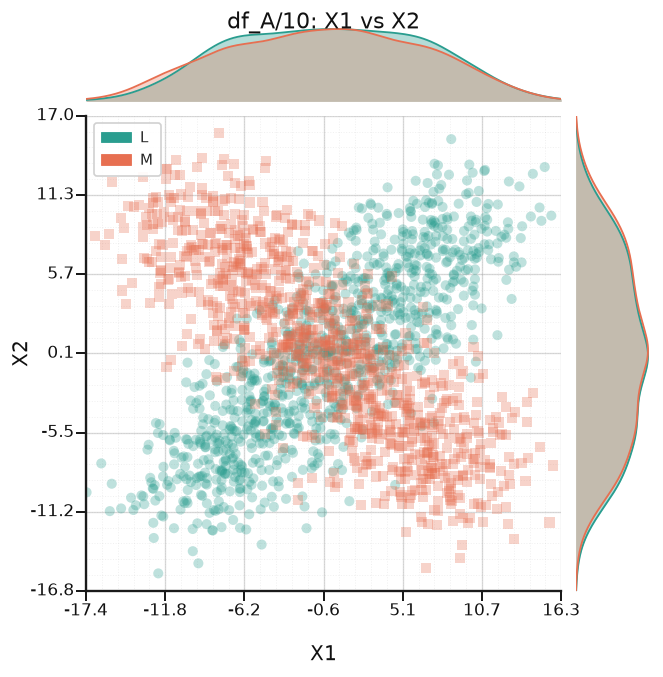

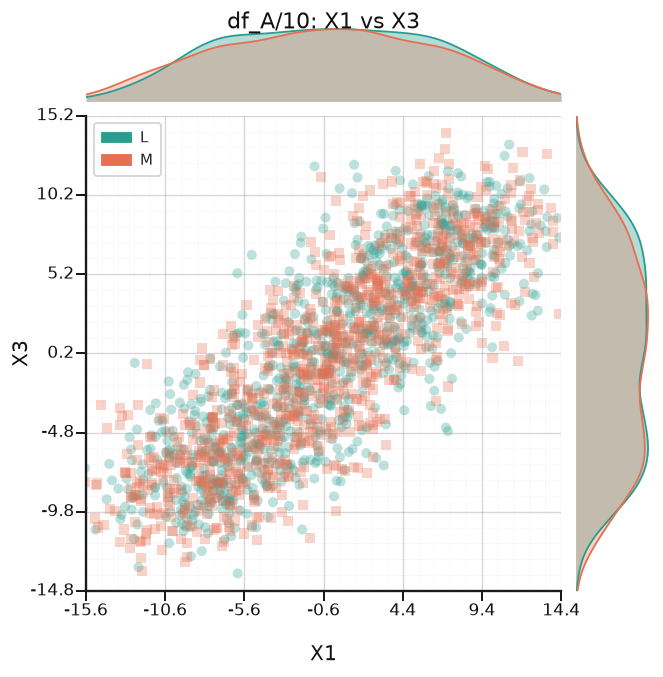

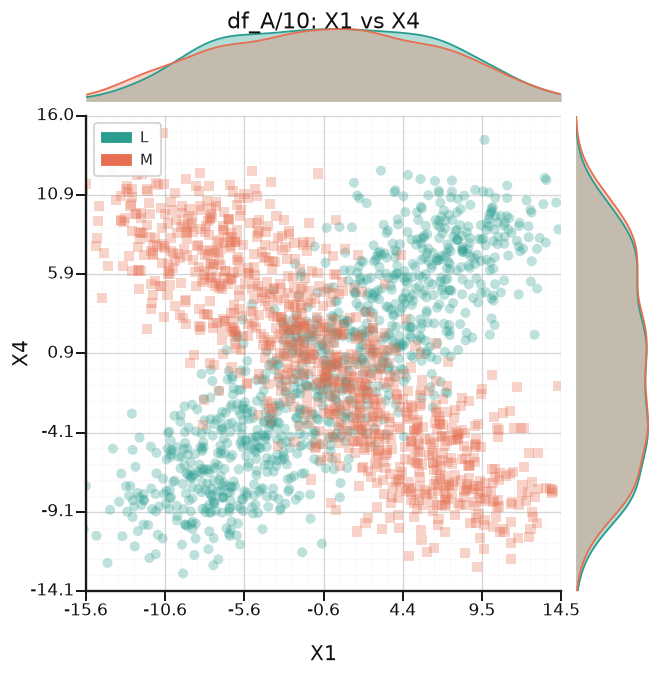

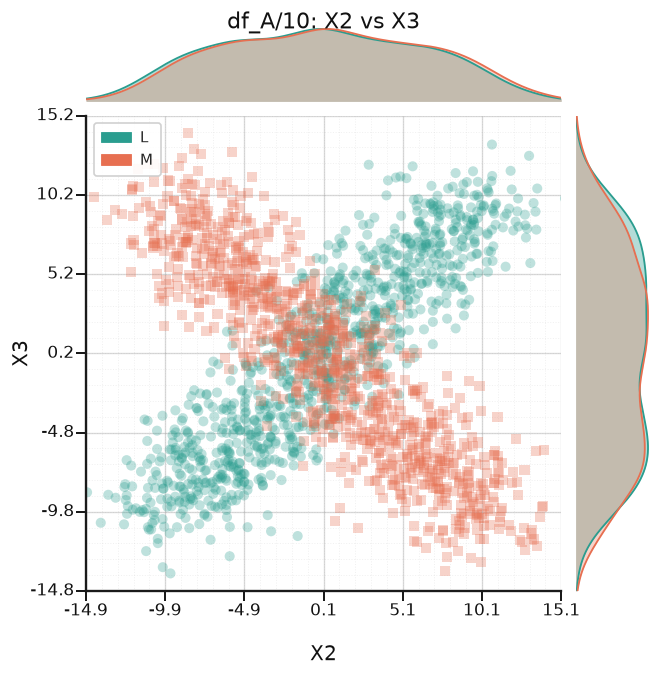

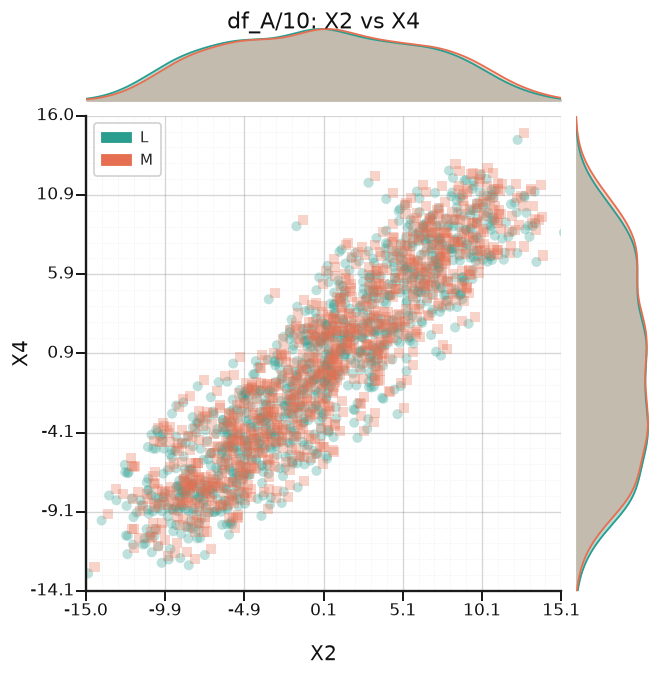

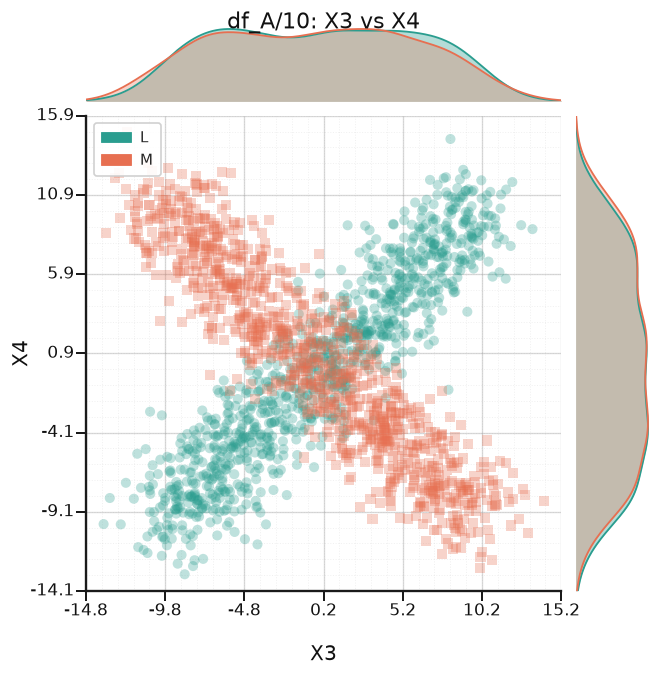

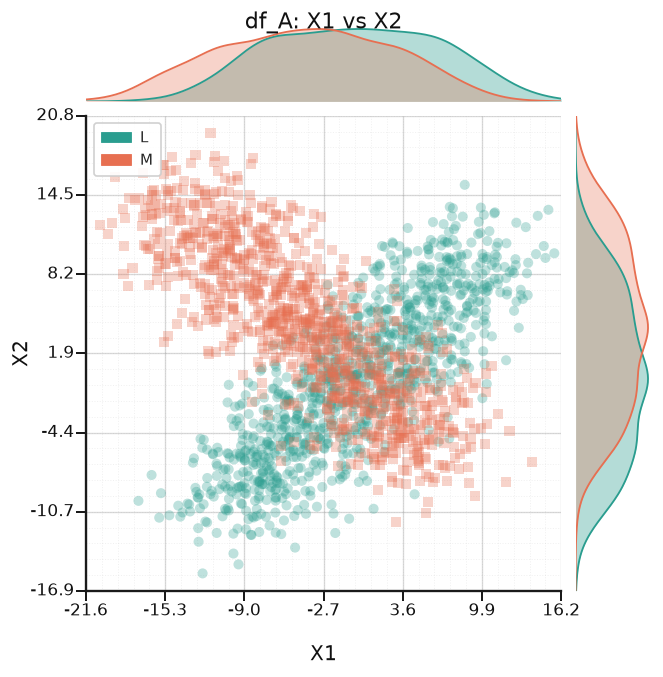

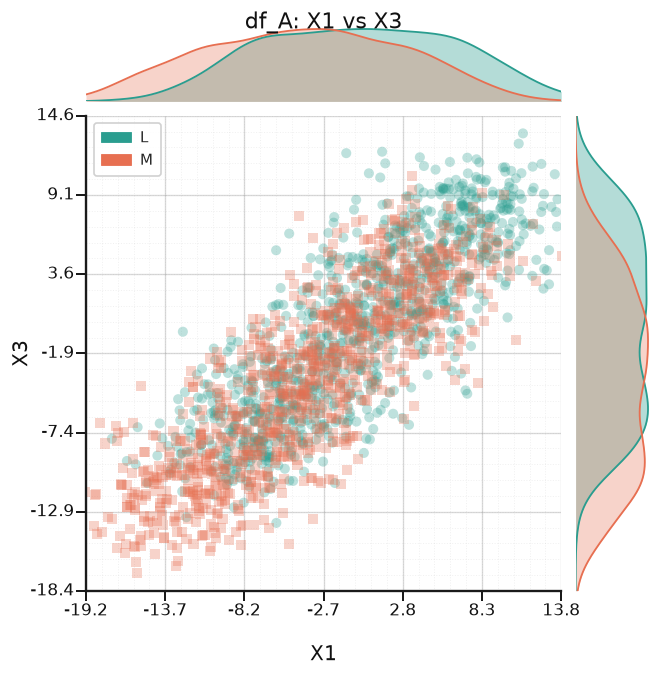

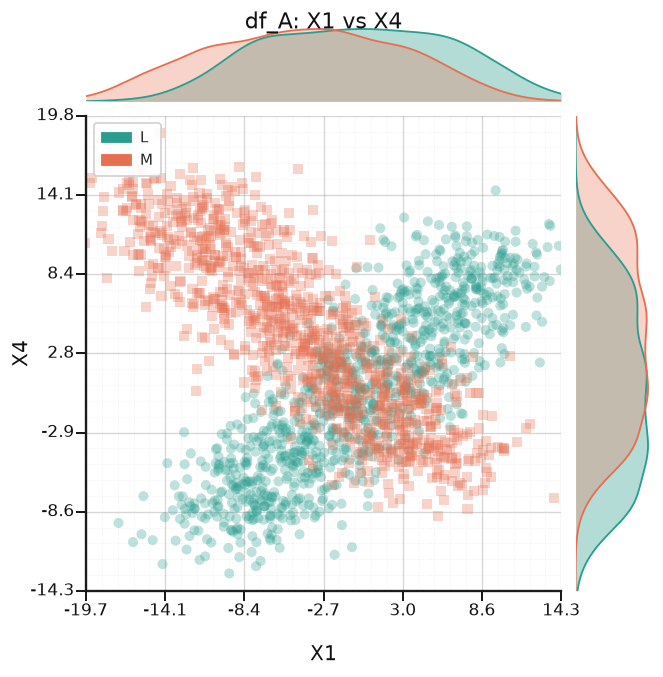

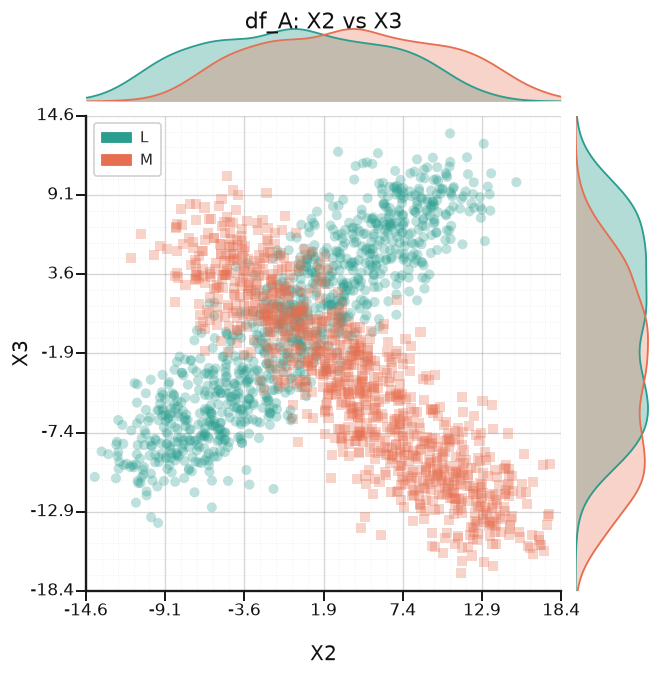

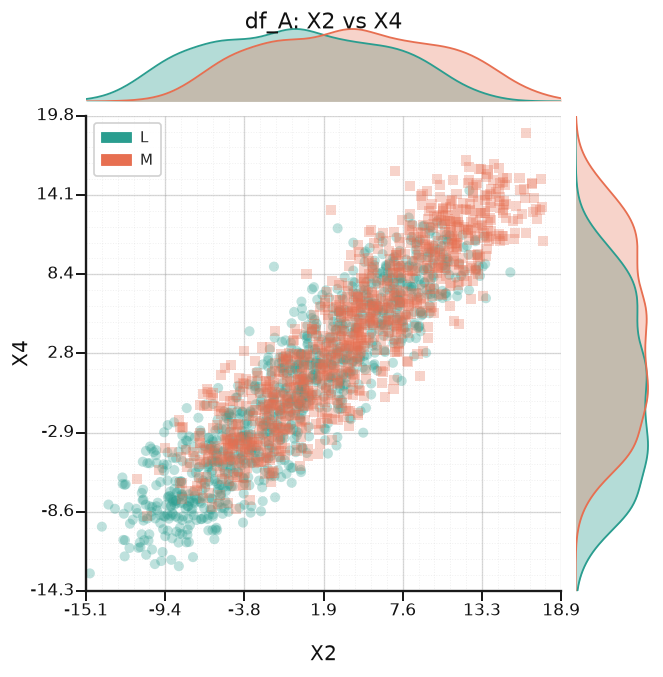

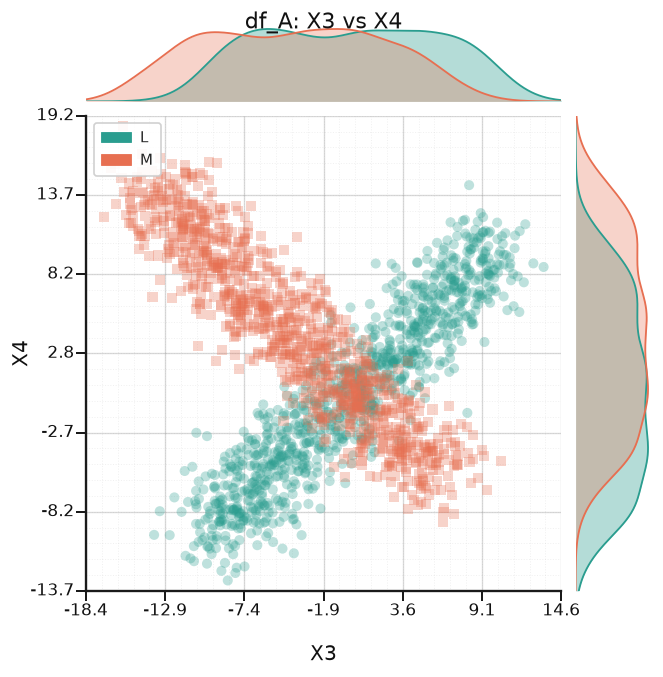

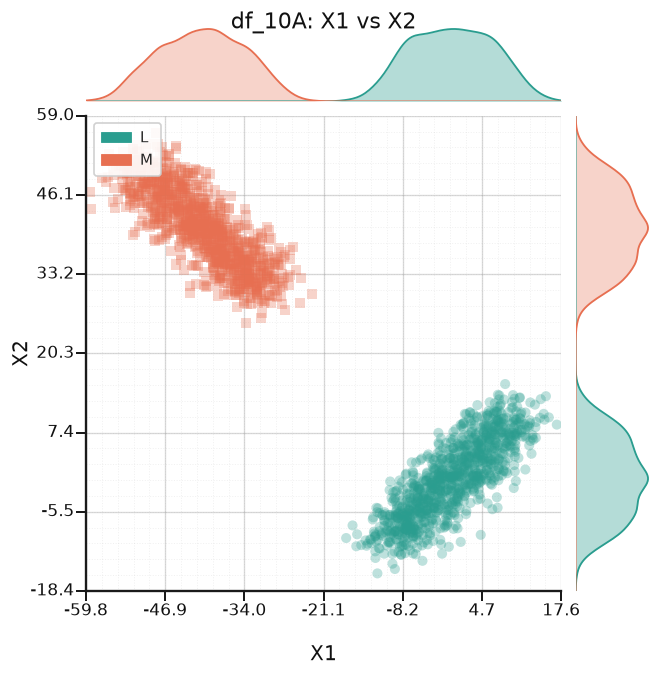

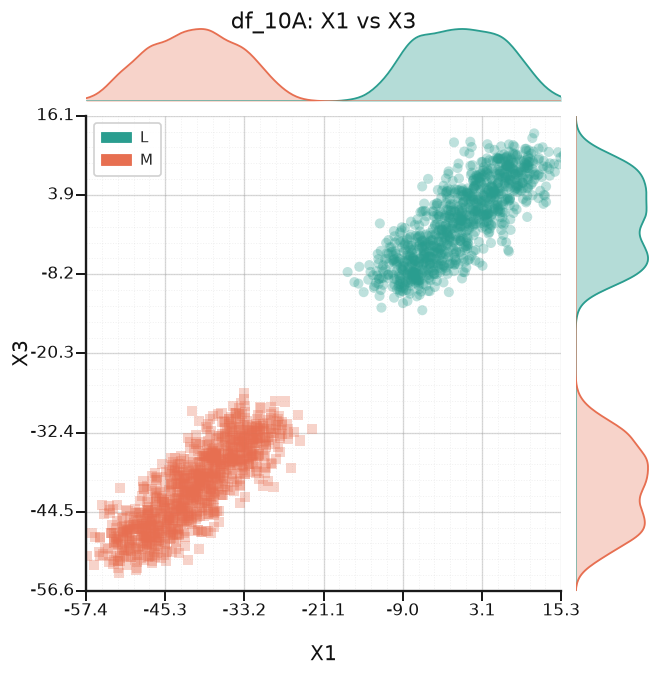

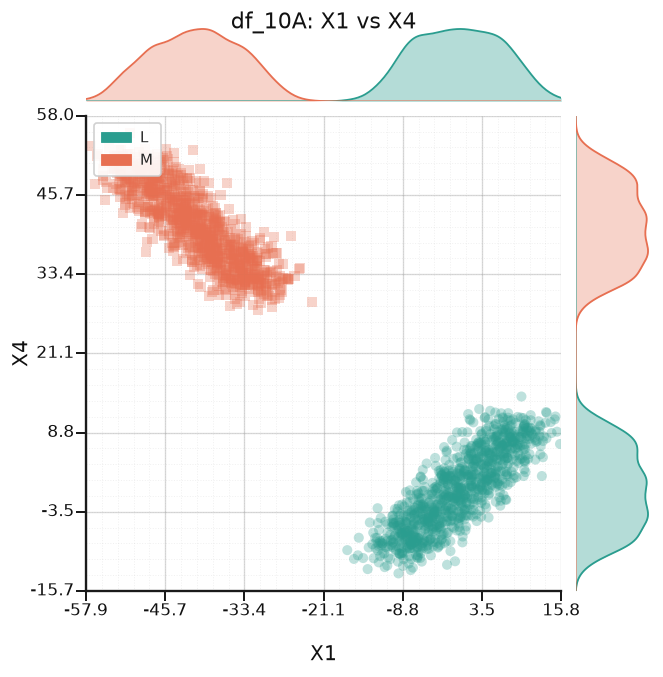

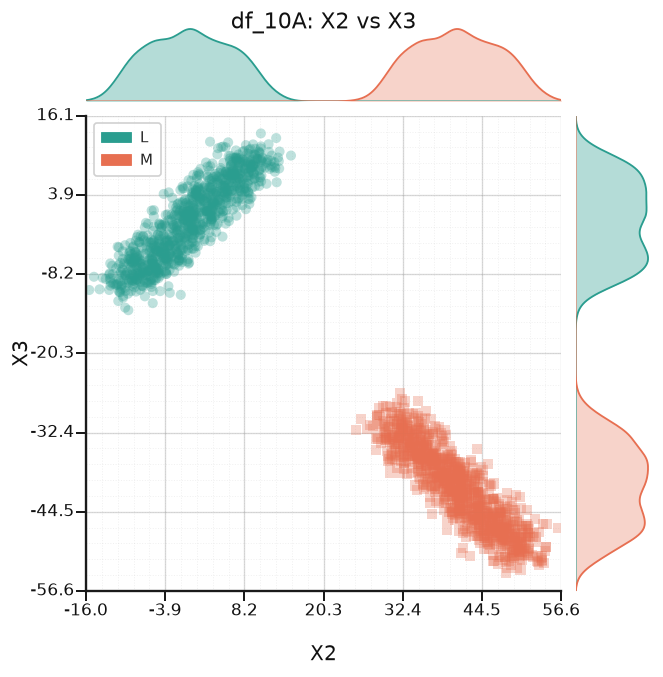

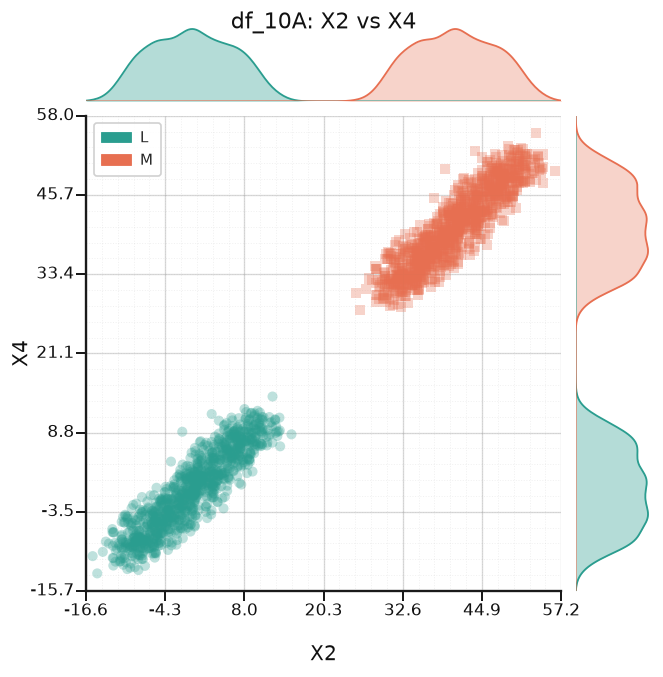

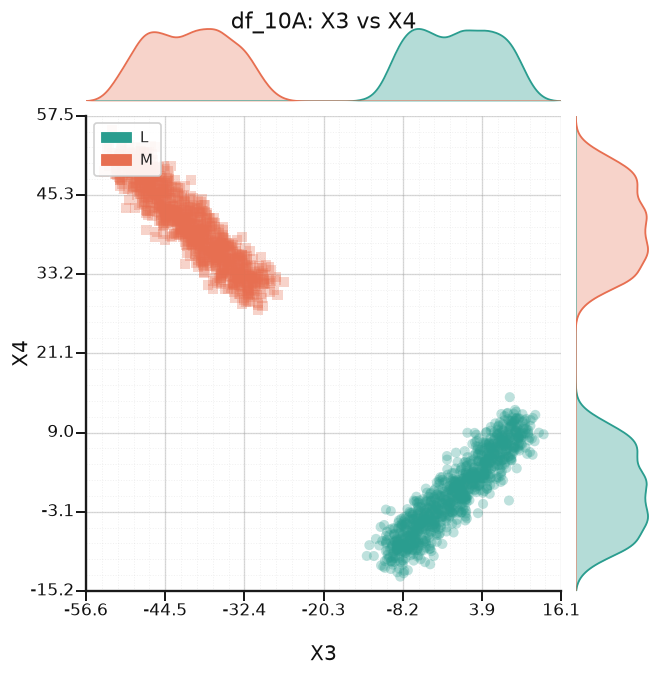

In [5]:
# ============================================================
# [1.4] Scatterplot по парам признаков (plots/scatterplot.py)
# ============================================================
# --- выбранные переменные: все пары этих признаков ---
SCATTER_FEATURES = FEATURES[:4]      # 4 признака -> 6 пар; можно FEATURES (6 -> 15 пар)

# --- параметры, регулируемые пользователем ---
SCATTER_PARAMS = {
    # фигура / квадратность
    'fig_size': 6.0,                 # сторона КВАДРАТНОЙ фигуры, дюймы
    'plot_fraction': 0.66,           # доля фигуры под квадратную область данных
    'square_data_area': True,        # одинаковый масштаб единиц данных по X и Y
    # оси
    'axes_show': True,
    'axes_color': '#1a1a1a',
    'axes_linewidth': 1.4,
    'axes_spines': 'left_bottom',    # 'frame' | 'left_bottom' | 'none'
    # рисок осей
    'ticks_show': True,
    'major_count': 7,                # число больших рисок (если major_step=None)
    'major_step': None,              # явный шаг больших рисок (переопределяет count)
    'major_start': None,             # значение первой большой риски
    'minor_count': 4,                # число малых рисок между двумя большими
    'tick_width': 1.2,
    # сетка
    'grid_show': True,
    'grid_minor': True,
    'grid_color': '#7a7a7a',
    'grid_alpha': 0.28,
    'grid_linestyle': '-',
    'grid_linewidth': 0.8,
    # прозрачность объектов
    'point_alpha': 0.30,
    'auto_alpha': False,             # True -> авто-прозрачность по числу точек
    # заглавия и легенда (отключаемость)
    'show_title': True,
    'show_legend': True,
    'legend_loc': 'upper left',
    # шрифты: размер и тип (family) каждого типа подписей
    'font_tick_size': 10,
    'font_label_size': 12,
    'font_title_size': 13,
    'font_legend_size': 9,
    'font_tick_family': 'sans-serif',
    'font_label_family': 'sans-serif',
    'font_title_family': 'sans-serif',
    'font_legend_family': 'sans-serif',
    # маргинальные плотности классов по осям
    'marginal_fraction': 0.16,       # высота/ширина полос плотностей относительно оси
    'marginal_gap': 0.02,
    'marginal_grid': 256,
    'marginal_alpha': {'L': 0.35, 'M': 0.30},   # прозрачность KDE каждого класса
    'marginal_linewidth': 1.1,
}

# форма и цвет точек по классам (разные по форме/цвету)
CLASS_SCATTER_STYLE = {
    'L': {'shape': 'circle',   'color': CLASS_COLORS['L'], 'alpha': SCATTER_PARAMS['point_alpha']},
    'M': {'shape': 'square',   'color': CLASS_COLORS['M'], 'alpha': SCATTER_PARAMS['point_alpha']},
}


def scatter_config(label, x_name, y_name):
    """Собирает конфиг scatter2d из пользовательских параметров."""
    p = SCATTER_PARAMS
    return {
        'figure': {
            'size': p['fig_size'],
            'plot_fraction': p['plot_fraction'],
            'colorbar': False,
            'title': f'df_{label}: {x_name} vs {y_name}' if p['show_title'] else None,
            'xlabel': x_name, 'ylabel': y_name,
            'title_size': p['font_title_size'],
            'label_size': p['font_label_size'],
            'legend': p['show_legend'],
            'legend_loc': p['legend_loc'],
            'legend_size': p['font_legend_size'],
        },
        'font': {
            'tick_size': p['font_tick_size'],
            'label_size': p['font_label_size'],
            'title_size': p['font_title_size'],
            'legend_size': p['font_legend_size'],
        },
        'axes': {
            'show': p['axes_show'], 'color': p['axes_color'],
            'linewidth': p['axes_linewidth'], 'spines': p['axes_spines'],
            'square_data_area': p['square_data_area'],
        },
        'ticks': {
            'show': p['ticks_show'],
            'major_count': p['major_count'], 'major_step': p['major_step'],
            'major_start': p['major_start'], 'minor_count': p['minor_count'],
            'width': p['tick_width'],
        },
        'grid': {
            'show': p['grid_show'], 'minor': p['grid_minor'],
            'color': p['grid_color'], 'alpha': p['grid_alpha'],
            'linestyle': p['grid_linestyle'], 'linewidth': p['grid_linewidth'],
        },
        'points': {'alpha': p['point_alpha'],
                   'alpha_mode': 'auto' if p['auto_alpha'] else 'fixed'},
        'classes': CLASS_SCATTER_STYLE,
        'density': {'show': False, 'mode': 'off'},
        'regression': {'show': False},
        'class_regression': {'show': False},
    }


def apply_font_families(result, x_name, y_name, label):
    """Назначает тип шрифта (family) каждому типу подписей после отрисовки."""
    p = SCATTER_PARAMS
    # подписи рисок (созданы движком scatterplot)
    for t in result.scaffold.label_artists:
        t.set_family(p['font_tick_family'])
    # заглавие и подписи осей — fig.texts, различаем по строке
    title_str = f'df_{label}: {x_name} vs {y_name}'
    for t in result.fig.texts:
        s = t.get_text()
        if s == title_str:
            t.set_family(p['font_title_family'])
        elif s in (x_name, y_name):
            t.set_family(p['font_label_family'])
    # легенда
    leg = result.ax.get_legend()
    if leg is not None:
        for t in leg.get_texts():
            t.set_family(p['font_legend_family'])


def draw_class_marginals(result, df, x_name, y_name):
    """KDE-плотности каждого класса вдоль X (сверху) и Y (справа), разные цвет/alpha."""
    p = SCATTER_PARAMS
    box = result.ax.get_position()
    top_h = min(p['marginal_fraction'] * box.height, 0.97 - (box.y1 + p['marginal_gap']))
    right_w = min(p['marginal_fraction'] * box.width, 0.98 - (box.x1 + p['marginal_gap']))
    grid_x = np.linspace(result.scaffold.xlim[0], result.scaffold.xlim[1], p['marginal_grid'])
    grid_y = np.linspace(result.scaffold.ylim[0], result.scaffold.ylim[1], p['marginal_grid'])

    top_ax = result.fig.add_axes([box.x0, box.y1 + p['marginal_gap'], box.width, top_h])
    right_ax = result.fig.add_axes([box.x1 + p['marginal_gap'], box.y0, right_w, box.height])
    for panel in (top_ax, right_ax):
        panel.set_facecolor('none')
        panel.set_xticks([]); panel.set_yticks([])
        for sp in panel.spines.values():
            sp.set_visible(False)
    top_ax.set_xlim(grid_x[0], grid_x[-1]); top_ax.set_ylim(0, 1.05)
    right_ax.set_ylim(grid_y[0], grid_y[-1]); right_ax.set_xlim(0, 1.05)

    for cls in CLASSES:
        color = result.class_styles[cls]['color']
        alpha = p['marginal_alpha'].get(cls, 0.3)
        mask = df[CLASS_COL] == cls
        for values, grid, panel, horizontal in (
            (df.loc[mask, x_name].to_numpy(), grid_x, top_ax, True),
            (df.loc[mask, y_name].to_numpy(), grid_y, right_ax, False),
        ):
            if np.ptp(values) == 0:
                continue
            z = gaussian_kde(values)(grid)
            z = z / z.max()
            if horizontal:
                panel.fill_between(grid, 0, z, color=color, alpha=alpha, linewidth=0)
                panel.plot(grid, z, color=color, linewidth=p['marginal_linewidth'])
            else:
                panel.fill_betweenx(grid, 0, z, color=color, alpha=alpha, linewidth=0)
                panel.plot(z, grid, color=color, linewidth=p['marginal_linewidth'])


def plot_pair(df, label, x_name, y_name):
    result = scatterplot.scatter2d(
        df, x=x_name, y=y_name, class_column=CLASS_COL, class_order=CLASSES,
        config=scatter_config(label, x_name, y_name),
    )
    draw_class_marginals(result, df, x_name, y_name)
    apply_font_families(result, x_name, y_name, label)
    return result


print(f'Выбранные признаки: {SCATTER_FEATURES}')
print(f'Пары: {list(combinations(SCATTER_FEATURES, 2))}')
PAIR_FIGURES = {}
for label, df in DF_Z.items():
    for x_name, y_name in combinations(SCATTER_FEATURES, 2):
        res = plot_pair(df, label, x_name, y_name)
        PAIR_FIGURES[(label, x_name, y_name)] = res
        plt.show()


## [1.5] Heat-map корреляций Пирсона и Спирмена

Для каждого `df_Z` строятся тепловые карты матриц корреляций:
- на всем датасете;
- отдельно в классе `L`;
- отдельно в классе `M`.

В каждой колонке — коэффициент Пирсона (линейная сопряжённость) и Спирмена
(ранговая монотонная сопряжённость).


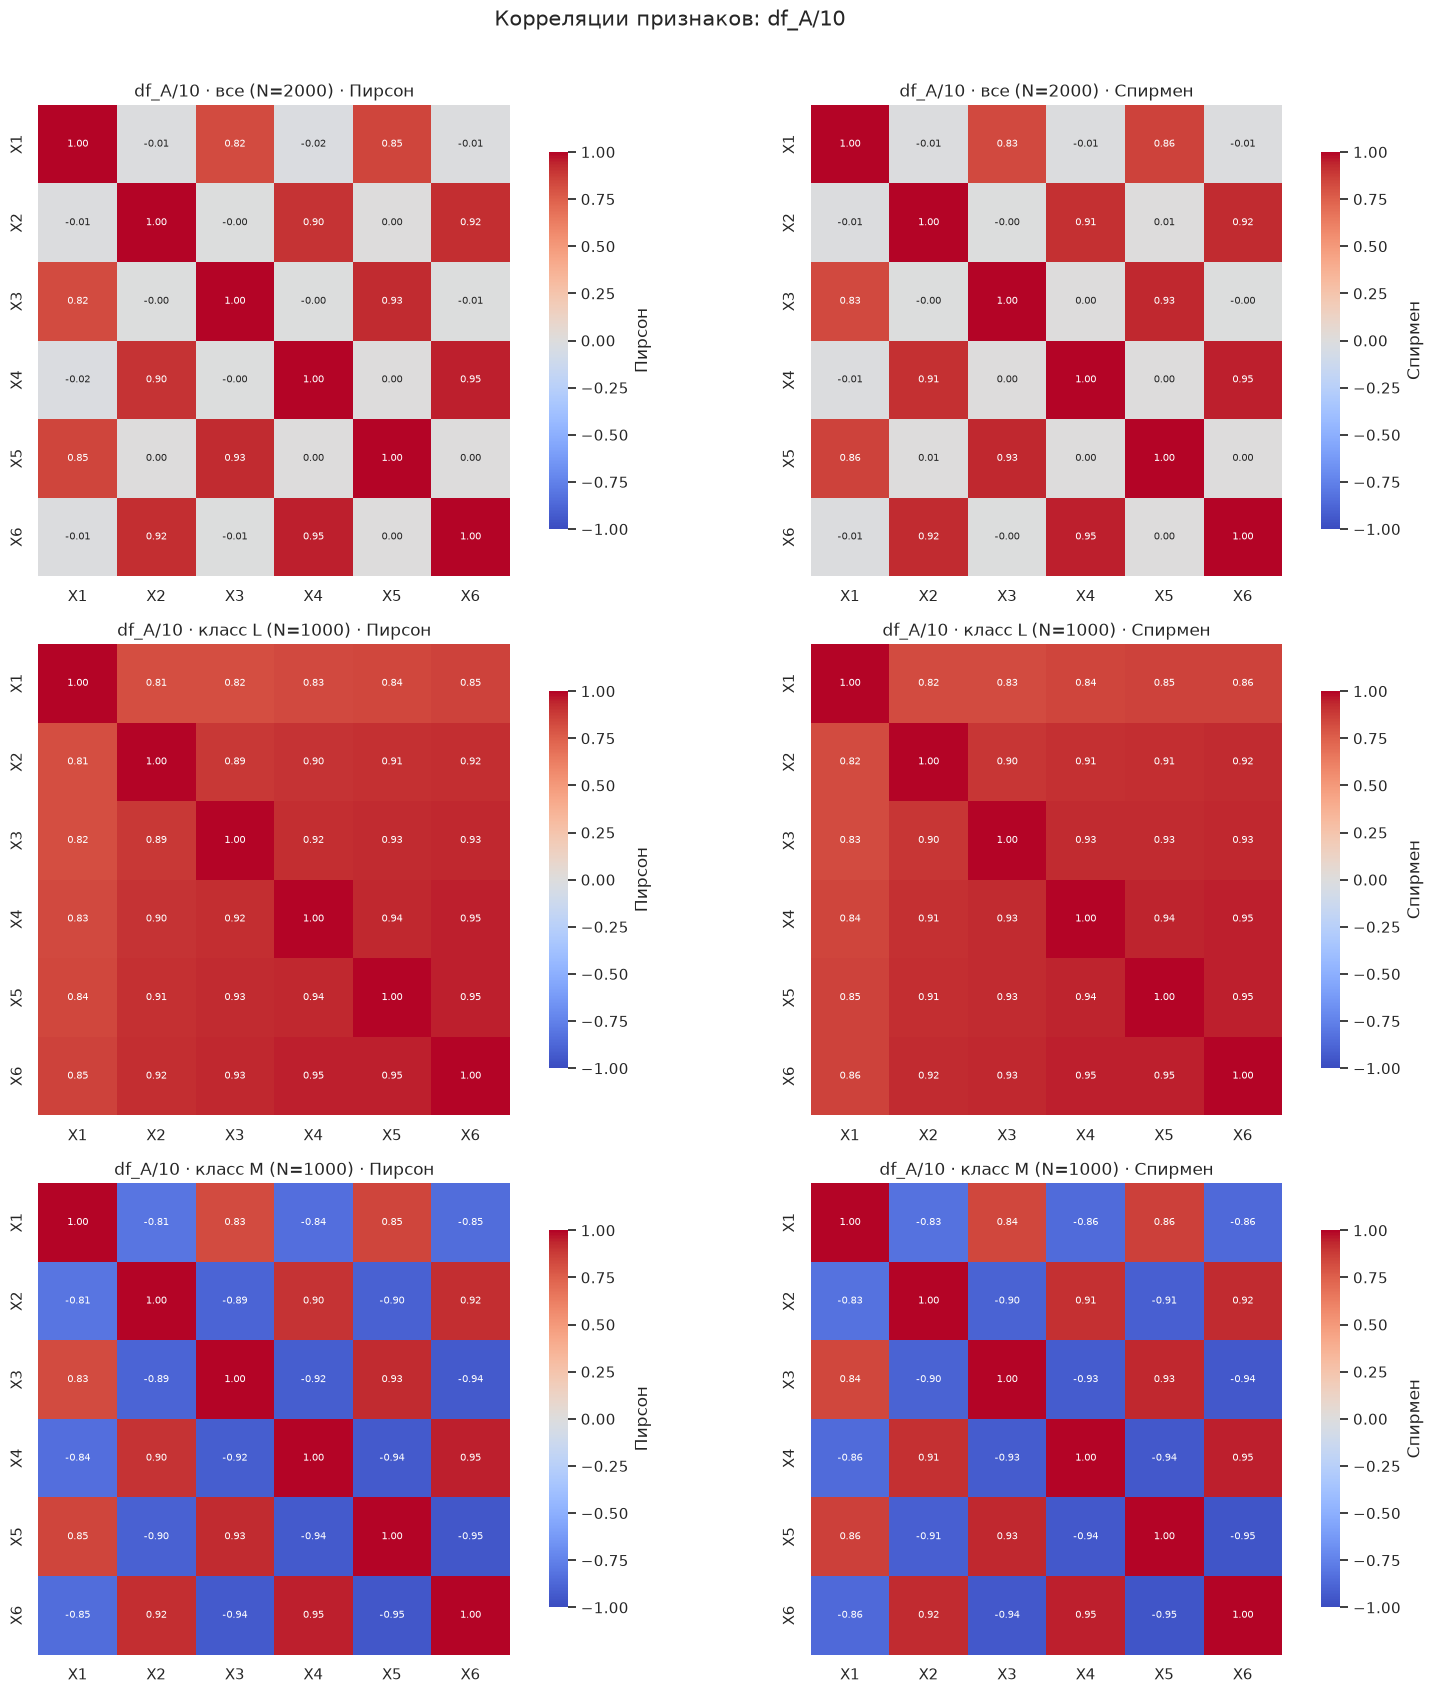

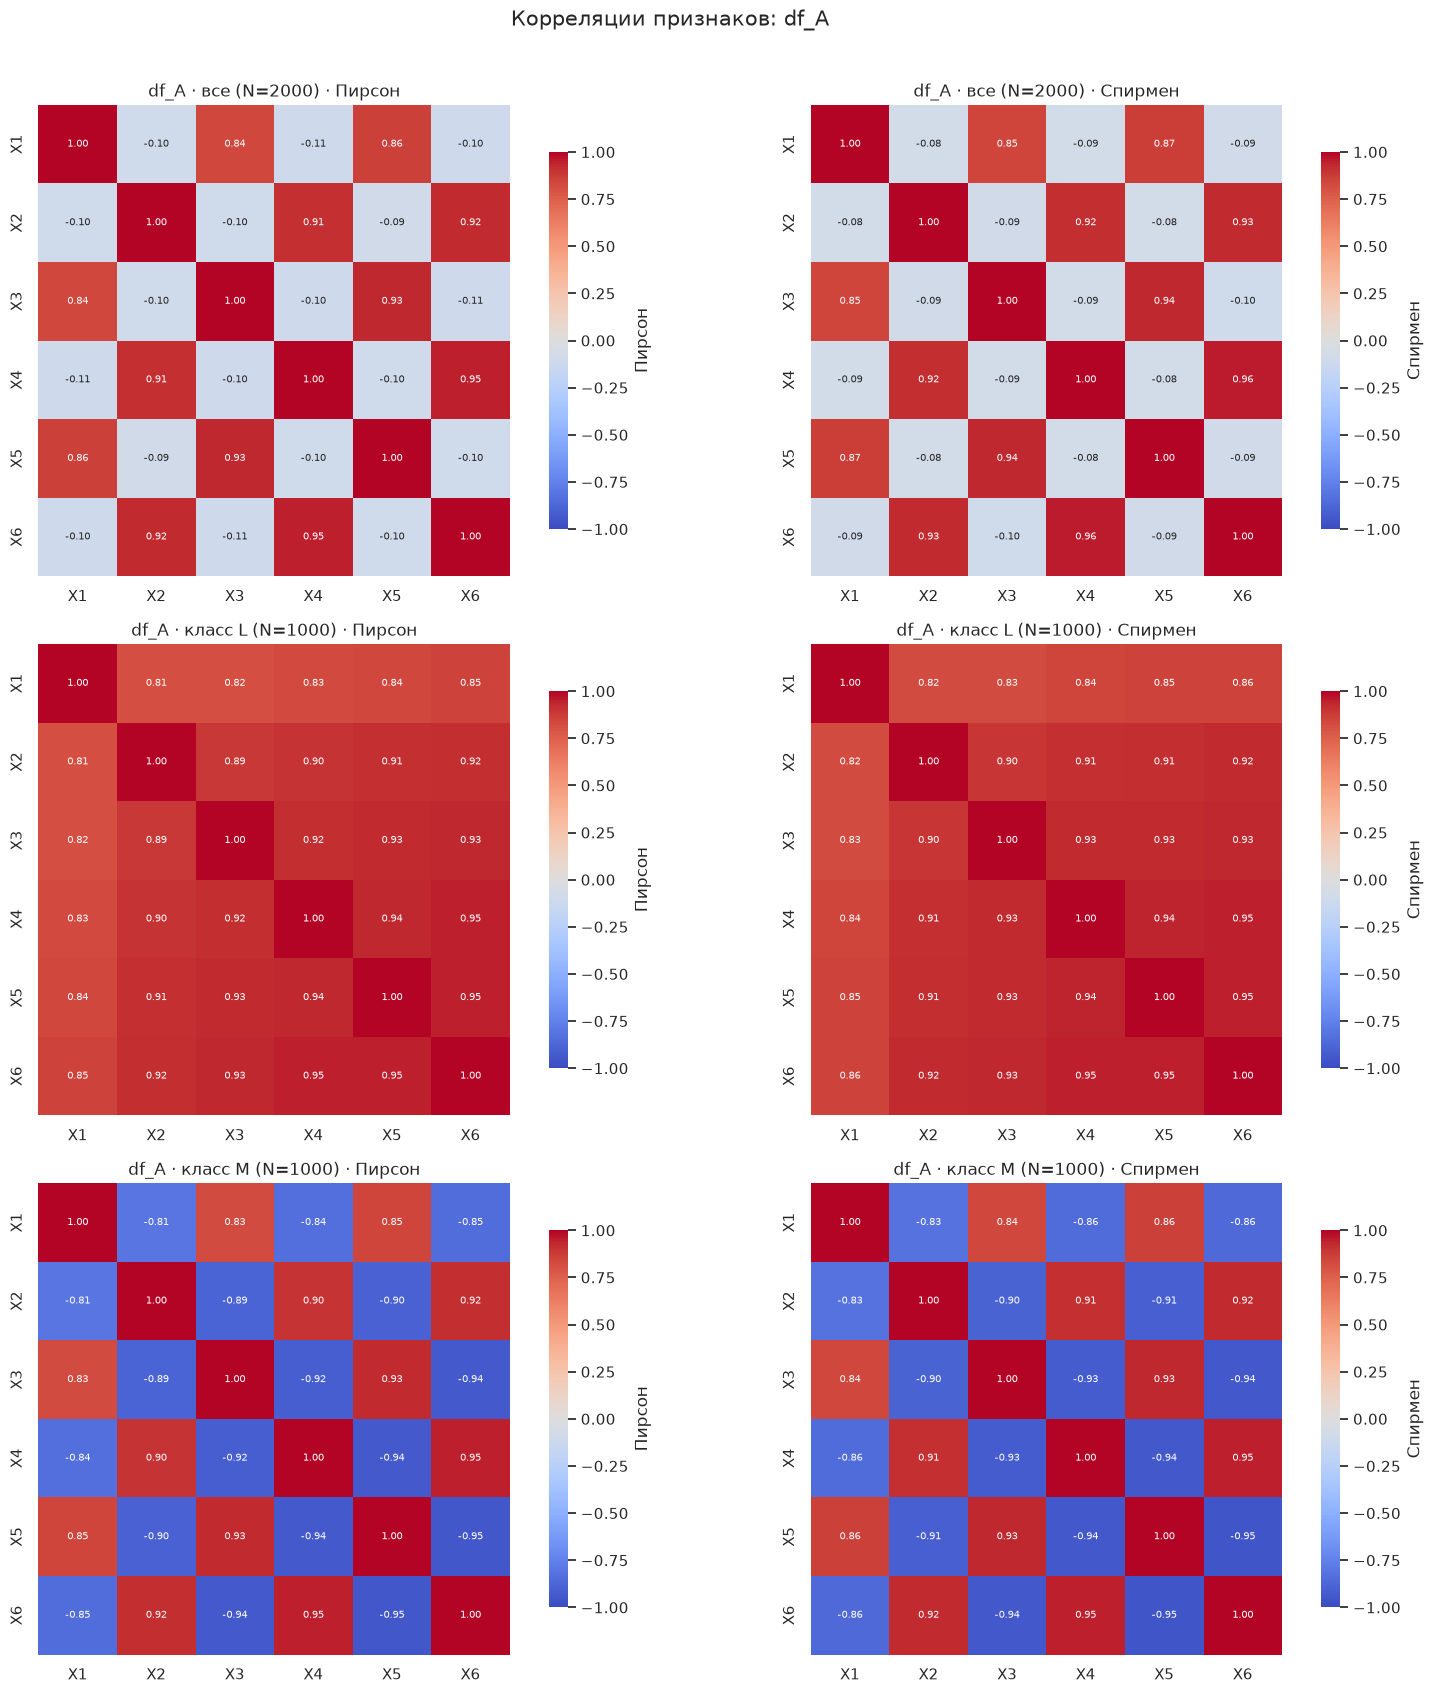

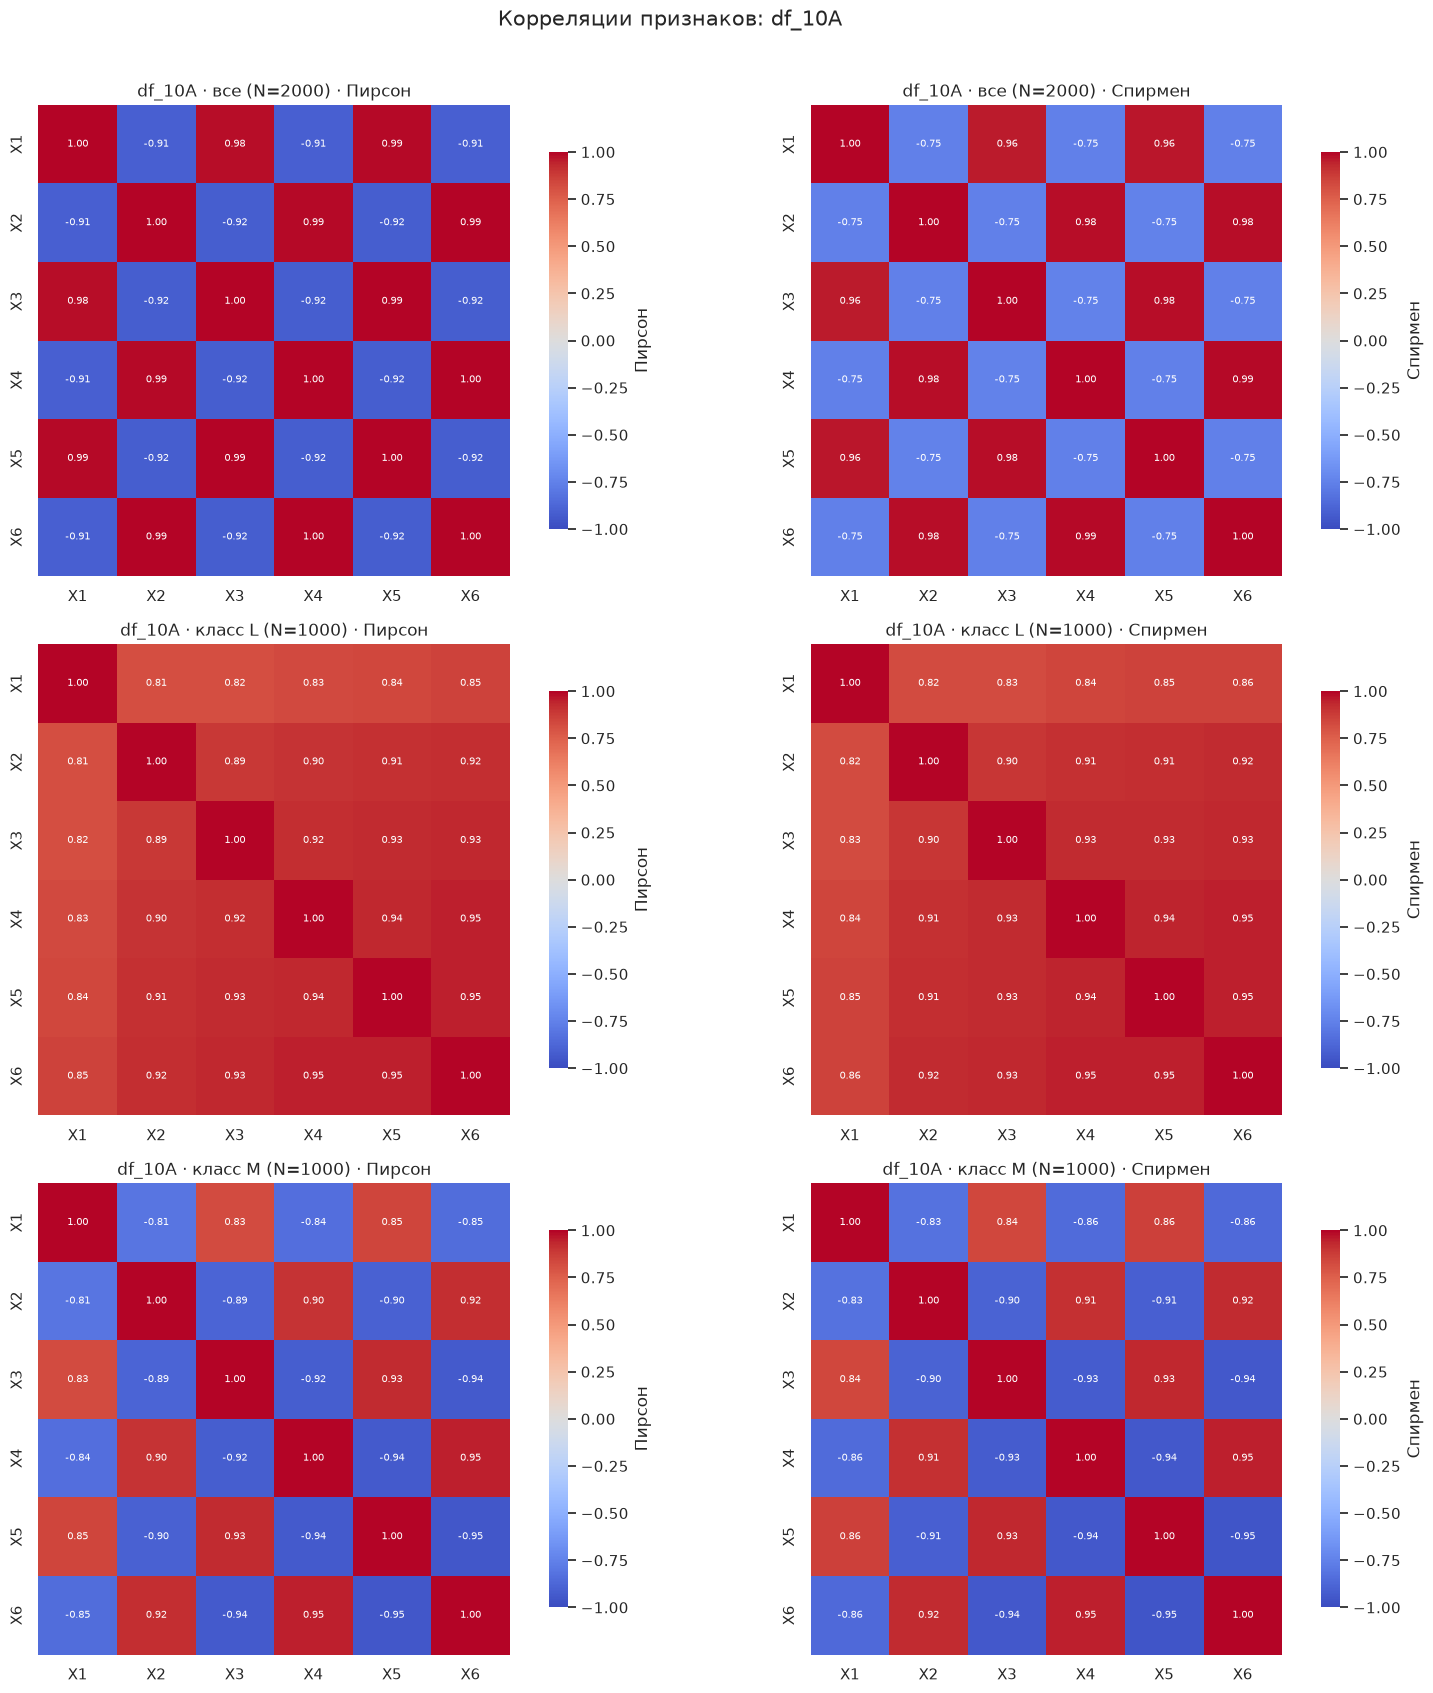


Сводка по сопряжённости пар признаков:
датасет  группа   метод  средняя |r|  макс |r|
df_A/10     все  Пирсон        0.362     0.947
df_A/10     все Спирмен        0.363     0.951
df_A/10 класс L  Пирсон        0.892     0.949
df_A/10 класс L Спирмен        0.899     0.951
df_A/10 класс M  Пирсон        0.893     0.951
df_A/10 класс M Спирмен        0.902     0.954
   df_A     все  Пирсон        0.422     0.952
   df_A     все Спирмен        0.416     0.956
   df_A класс L  Пирсон        0.892     0.949
   df_A класс L Спирмен        0.899     0.951
   df_A класс M  Пирсон        0.893     0.951
   df_A класс M Спирмен        0.902     0.954
 df_10A     все  Пирсон        0.946     0.996
 df_10A     все Спирмен        0.840     0.988
 df_10A класс L  Пирсон        0.892     0.949
 df_10A класс L Спирмен        0.899     0.951
 df_10A класс M  Пирсон        0.893     0.951
 df_10A класс M Спирмен        0.902     0.954


In [6]:
# ============================================================
# [1.5] Heat-map корреляций Пирсона и Спирмена (plots/)
# ============================================================
CORR_METHODS = [('pearson', 'Пирсон'), ('spearman', 'Спирмен')]


def plot_correlation_heatmaps(df, label):
    groups = [('все', df)] + [(f'класс {c}', df[df[CLASS_COL] == c]) for c in CLASSES]
    fig, axes = plt.subplots(nrows=len(groups), ncols=2, figsize=(16, 17))
    for i, (gname, gdata) in enumerate(groups):
        for j, (method, mname) in enumerate(CORR_METHODS):
            ax = axes[i, j]
            corr = gdata[FEATURES].corr(method=method)
            sns.heatmap(
                corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1,
                fmt='.2f', ax=ax, square=True,
                annot_kws={'size': 7},
                cbar_kws={'shrink': 0.8, 'label': mname},
            )
            ax.set_title(f'df_{label} · {gname} (N={len(gdata)}) · {mname}')
    fig.suptitle(f'Корреляции признаков: df_{label}', fontsize=15, y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.985))
    return fig


for label, df in DF_Z.items():
    fig = plot_correlation_heatmaps(df, label)
    plt.show()

# --- краткая сводка: средняя |корреляция| по парам признаков ---
rows = []
for label, df in DF_Z.items():
    for gname, gdata in [('все', df)] + [(f'класс {c}', df[df[CLASS_COL] == c]) for c in CLASSES]:
        for method, mname in CORR_METHODS:
            m = gdata[FEATURES].corr(method=method).to_numpy()
            iu = np.triu_indices_from(m, k=1)
            rows.append({'датасет': f'df_{label}', 'группа': gname, 'метод': mname,
                         'средняя |r|': np.abs(m[iu]).mean(),
                         'макс |r|': np.abs(m[iu]).max()})
print('\nСводка по сопряжённости пар признаков:')
print(pd.DataFrame(rows).round(3).to_string(index=False))


### Итог

- `df_Z` сгенерированы для `Z = A/10, A, 10A` (по 1000 объектов в классах `L` и `M`);
- [1.2] получена табличная статистика, включая размерность, типы, число классов,
  оценки выборки и числа объектов с `NaN`/`0` по классам;
- [1.3] построены raincloud+boxplot по каждому признаку (с настраиваемыми
  параметрами ящика: Range/IQR/другие квантили);
- [1.4] построены scatterplot-ы для всех пар выбранных признаков с разными
  маркерами классов и маргинальными KDE-плотностями, все параметры вынесены
  в `SCATTER_PARAMS`;
- [1.5] оценена сопряжённость признаков heat-map-ами Пирсона и Спирмена
  на всем датасете и в каждом классе.
